# Load and preprocess time series data files

In [3]:
path = '../../../data/FRED/CORESTICKM159SFRBATL.csv'

## Load data from CSV

### Having datetime column

In [4]:
import pandas as pd
df = pd.read_csv(path)

df

,observation_date,CORESTICKM159SFRBATL
0,1968-01-01,3.651861
1,1968-02-01,3.673819
2,1968-03-01,4.142164
3,1968-04-01,4.155828
4,1968-05-01,4.088245
...,...,...
682,2024-11-01,3.876177
683,2024-12-01,3.746553
684,2025-01-01,3.625276
685,2025-02-01,3.516515


In [5]:
df.observation_date

0      1968-01-01
1      1968-02-01
2      1968-03-01
3      1968-04-01
4      1968-05-01
          ...    
682    2024-11-01
683    2024-12-01
684    2025-01-01
685    2025-02-01
686    2025-03-01
Name: observation_date, Length: 687, dtype: str

In [4]:
df.observation_date.dt.to_period('Q')

AttributeError: Can only use .dt accessor with datetimelike values

In [6]:
df.observation_date = pd.to_datetime(df.observation_date)

df.observation_date

0     1968-01-01
1     1968-02-01
2     1968-03-01
3     1968-04-01
4     1968-05-01
         ...    
682   2024-11-01
683   2024-12-01
684   2025-01-01
685   2025-02-01
686   2025-03-01
Name: observation_date, Length: 687, dtype: datetime64[us]

In [7]:
df.observation_date.dt.to_period('Q')

0      1968Q1
1      1968Q1
2      1968Q1
3      1968Q2
4      1968Q2
        ...  
682    2024Q4
683    2024Q4
684    2025Q1
685    2025Q1
686    2025Q1
Name: observation_date, Length: 687, dtype: period[Q-DEC]

In [8]:
df = pd.read_csv(path, parse_dates=['observation_date'])

df

,observation_date,CORESTICKM159SFRBATL
0,1968-01-01,3.651861
1,1968-02-01,3.673819
2,1968-03-01,4.142164
3,1968-04-01,4.155828
4,1968-05-01,4.088245
...,...,...
682,2024-11-01,3.876177
683,2024-12-01,3.746553
684,2025-01-01,3.625276
685,2025-02-01,3.516515


In [9]:
df.observation_date

0     1968-01-01
1     1968-02-01
2     1968-03-01
3     1968-04-01
4     1968-05-01
         ...    
682   2024-11-01
683   2024-12-01
684   2025-01-01
685   2025-02-01
686   2025-03-01
Name: observation_date, Length: 687, dtype: datetime64[us]

### Having no datetime column

In [5]:
path = '../../../data/EIA/demand_cal_historical_datetime-split.csv'

In [6]:
df = pd.read_csv(path)

df

,year,month,day,hour,value
0,2019,1,1,0,28487
1,2019,1,1,1,30507
2,2019,1,1,2,33785
3,2019,1,1,3,33796
4,2019,1,1,4,32764
...,...,...,...,...,...
55087,2025,4,14,7,27851
55088,2025,4,14,8,26228
55089,2025,4,14,9,25482
55090,2025,4,14,10,24600


In [7]:
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])

df

,year,month,day,hour,value,datetime
0,2019,1,1,0,28487,2019-01-01 00:00:00
1,2019,1,1,1,30507,2019-01-01 01:00:00
2,2019,1,1,2,33785,2019-01-01 02:00:00
3,2019,1,1,3,33796,2019-01-01 03:00:00
4,2019,1,1,4,32764,2019-01-01 04:00:00
...,...,...,...,...,...,...
55087,2025,4,14,7,27851,2025-04-14 07:00:00
55088,2025,4,14,8,26228,2025-04-14 08:00:00
55089,2025,4,14,9,25482,2025-04-14 09:00:00
55090,2025,4,14,10,24600,2025-04-14 10:00:00


## Temporal column to index

In [9]:
df.head(10)

,year,month,day,hour,value,datetime
0,2019,1,1,0,28487,2019-01-01 00:00:00
1,2019,1,1,1,30507,2019-01-01 01:00:00
2,2019,1,1,2,33785,2019-01-01 02:00:00
3,2019,1,1,3,33796,2019-01-01 03:00:00
4,2019,1,1,4,32764,2019-01-01 04:00:00
5,2019,1,1,5,31673,2019-01-01 05:00:00
6,2019,1,1,6,30496,2019-01-01 06:00:00
7,2019,1,1,7,29112,2019-01-01 07:00:00
8,2019,1,1,8,27841,2019-01-01 08:00:00
9,2019,1,1,9,26876,2019-01-01 09:00:00


In [10]:
df.datetime.dt.to_period('Q')

0        2019Q1
1        2019Q1
2        2019Q1
3        2019Q1
4        2019Q1
          ...  
55087    2025Q2
55088    2025Q2
55089    2025Q2
55090    2025Q2
55091    2025Q2
Name: datetime, Length: 55092, dtype: period[Q-DEC]

In [11]:
df_idx = df.set_index('datetime')

df_idx

,year,month,day,hour,value
datetime,,,,,
2019-01-01 00:00:00,2019,1,1,0,28487
2019-01-01 01:00:00,2019,1,1,1,30507
2019-01-01 02:00:00,2019,1,1,2,33785
2019-01-01 03:00:00,2019,1,1,3,33796
2019-01-01 04:00:00,2019,1,1,4,32764
...,...,...,...,...,...
2025-04-14 07:00:00,2025,4,14,7,27851
2025-04-14 08:00:00,2025,4,14,8,26228
2025-04-14 09:00:00,2025,4,14,9,25482


In [12]:
df_idx.index.to_period('Q')

PeriodIndex(['2019Q1', '2019Q1', '2019Q1', '2019Q1', '2019Q1', '2019Q1',
             '2019Q1', '2019Q1', '2019Q1', '2019Q1',
             ...
             '2025Q2', '2025Q2', '2025Q2', '2025Q2', '2025Q2', '2025Q2',
             '2025Q2', '2025Q2', '2025Q2', '2025Q2'],
            dtype='period[Q-DEC]', name='datetime', length=55092)

In [14]:
df_idx.resample('QE').value.sum( )

datetime
2019-03-31    57714602
2019-06-30    62958899
2019-09-30    79886963
2019-12-31    63807824
2020-03-31    60557852
2020-06-30    62710794
2020-09-30    80256351
2020-12-31    65004520
2021-03-31    58939806
2021-06-30    65255835
2021-09-30    80536685
2021-12-31    64274326
2022-03-31    60264094
2022-06-30    65643181
2022-09-30    83178407
2022-12-31    64802198
2023-03-31    61662174
2023-06-30    60985029
2023-09-30    78392978
2023-12-31    64132218
2024-03-31    60238266
2024-06-30    62705017
2024-09-30    81188363
2024-12-31    66167043
2025-03-31    60886222
2025-06-30     8956588
Freq: QE-DEC, Name: value, dtype: int64

<Axes: xlabel='datetime'>

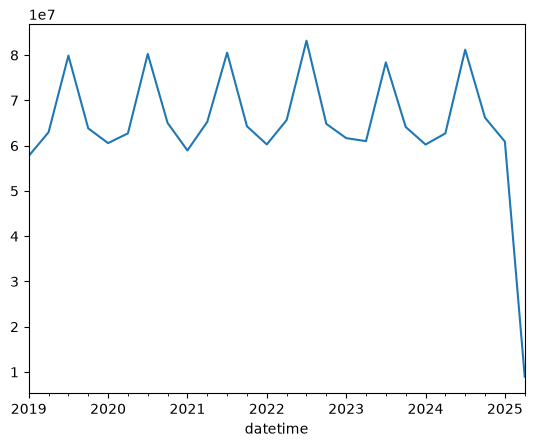

In [15]:
df_idx.resample('QE').value.sum().plot.line()

<Axes: xlabel='datetime'>

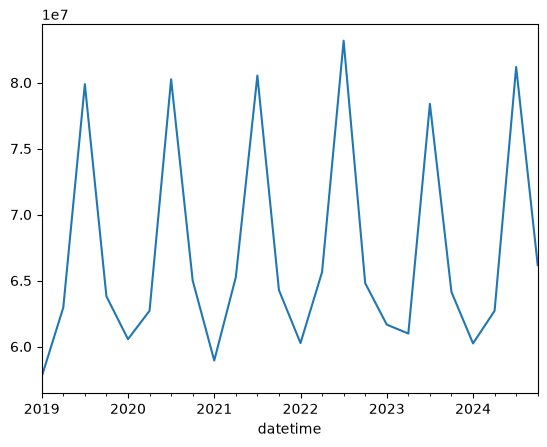

In [17]:
df_idx.loc[:'2024'].resample('QE').value.sum().plot.line()

## Load data from Excel

In [18]:
path = '../../../data/FRED/CORESTICKM159SFRBATL.xlsx'

In [19]:
pd.read_excel(path)

,FRED Graph Observations,Unnamed: 1,Unnamed: 2
0,"Federal Reserve Economic Data, Federal Reserve...",NaN,NaN
1,Link: https://fred.stlouisfed.org,NaN,NaN
2,Help: https://fredhelp.stlouisfed.org,NaN,NaN
3,This data may be copyrighted. Please refer to ...,NaN,NaN
4,File Created: 2025-04-14 6:07 am CDT,NaN,NaN
5,NaN,NaN,NaN
6,CORESTICKM159SFRBATL,Sticky Price Consumer Price Index less Food an...,Data Updated: 2025-04-10


In [20]:
pd.read_excel(path, sheet_name=1)

,observation_date,CORESTICKM159SFRBATL
0,1968-01-01,3.651861
1,1968-02-01,3.673819
2,1968-03-01,4.142164
3,1968-04-01,4.155828
4,1968-05-01,4.088245
...,...,...
682,2024-11-01,3.876177
683,2024-12-01,3.746553
684,2025-01-01,3.625276
685,2025-02-01,3.516515


In [17]:
df = pd.read_excel(path, sheet_name=1)

df

,observation_date,CORESTICKM159SFRBATL
0,1968-01-01,3.651861
1,1968-02-01,3.673819
...,...,...
685,2025-02-01,3.516515
686,2025-03-01,3.257815


In [22]:
df = pd.read_excel(path, sheet_name=1, index_col='observation_date')

df

,CORESTICKM159SFRBATL
observation_date,
1968-01-01,3.651861
1968-02-01,3.673819
1968-03-01,4.142164
1968-04-01,4.155828
1968-05-01,4.088245
...,...
2024-11-01,3.876177
2024-12-01,3.746553
2025-01-01,3.625276


In [23]:
df.index

DatetimeIndex(['1968-01-01', '1968-02-01', '1968-03-01', '1968-04-01',
               '1968-05-01', '1968-06-01', '1968-07-01', '1968-08-01',
               '1968-09-01', '1968-10-01',
               ...
               '2024-06-01', '2024-07-01', '2024-08-01', '2024-09-01',
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01'],
              dtype='datetime64[us]', name='observation_date', length=687,
              freq=None)

In [19]:
df = pd.read_excel(path, sheet_name=1, parse_dates=True, index_col=0)

df

,CORESTICKM159SFRBATL
observation_date,
1968-01-01,3.651861
1968-02-01,3.673819
...,...
2025-02-01,3.516515
2025-03-01,3.257815
